# 06 · Claim severity GLM (Milestone 8)

**Goal:** model **how big** a paid flood claim is (its **severity**), as the partner of the frequency model in notebook 05 (**how often** claims happen). Expected loss cost per policy-year = frequency × severity.

The model is a **Gamma GLM with a log link**, fitted to **individual paid claims** in 2025 dollars. As in the frequency model, each feature *multiplies* the expected claim size by its **relativity** e^β, and calendar year is a factor so storm years don't distort the building relativities.

What this notebook does:
- **(a)** Explore the severity distribution: log-scale histogram, percentiles, how much of the money sits in the largest claims, and how many claims hit their NFIP coverage limit.
- **(b)** Large losses: model uncapped vs capped claims (95th and 99th percentile), the large-loss load that puts capped dollars back, and a recommendation.
- **(c)** Build the model step by step from the Milestone 6 shortlist (deviance, AIC, F / likelihood-ratio tests, storm-aware Wald tests, leave-one-year-out), including geography.
- **(d)** The final relativity table (e^β, 95% CIs, base levels stated).
- **(e)** Frequency and severity relativities side by side: which factors drive which.
- **(f)** Fit checks (residuals; Gamma vs lognormal) and held-out evaluation (actual vs expected, decile lift, no-features baseline).

**Data:** paid claims rebuilt from `data/raw/` and reconciled to `data/processed/va_model_data.parquet`. **Code:** `src/models/severity_glm.py` (this notebook only calls it), `src/models/frequency_glm.py`, `src/validation.py`. **Write-up:** `reports/05_severity_glm.md`.

> Area-level analysis of aggregated public data. Nothing here is a prediction for an individual property.

In [1]:
import hashlib
import json
import sys
import warnings
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import build_dataset as bd                    # our own modules in src/
import validation as val
from models import frequency_glm as fg
from models import severity_glm as sv

warnings.filterwarnings("ignore", category=RuntimeWarning, module="statsmodels")
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

# --- Chart style: the same quiet look as notebooks 01-05 ---------------------
BLUE = "#2a78d6"     # severity model
ORANGE = "#eb6834"   # catastrophe years / frequency / comparison
AQUA = "#1baf7a"     # third series (pure premium, lognormal)
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "font.size": 9.5,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "legend.frameon": False, "text.usetex": False, "text.parse_math": False,
})

def save(fig, name):
    path = FIG / f"06_{name}.png"
    fig.savefig(path)
    print(f"saved {path.relative_to(ROOT)}")

def log_rel_axis(ax, lo=0.25, hi=4, axis="x"):
    # Relativities on a LOG scale, so x2 and x0.5 are the same distance from 1.
    ticks = [t for t in [0.1, 0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 8] if lo <= t <= hi]
    a = ax.xaxis if axis == "x" else ax.yaxis
    (ax.set_xscale if axis == "x" else ax.set_yscale)("log")
    (ax.set_xlim if axis == "x" else ax.set_ylim)(lo, hi)
    a.set_major_locator(mticker.FixedLocator(ticks))
    a.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:g}"))
    a.set_minor_locator(mticker.NullLocator())
    (ax.axvline if axis == "x" else ax.axhline)(1, color=MUTED, lw=1, ls="--", zorder=1)

def dollars(v, p=None):
    return f"${v / 1000:,.0f}K" if abs(v) >= 1000 else f"${v:,.0f}"

def fmt_p(p):
    if pd.isna(p):
        return "n/a"
    return "<0.0001" if p < 1e-4 else f"{p:.4f}"

LABELS = {"flood_zone_group": "Flood zone", "occupancy_group": "Occupancy", "floors_group": "Floors",
          "elevated": "Elevated", "primary_residence": "Primary residence", "post_firm": "Post-FIRM",
          "construction_band": "Year built", "building_coverage_band": "Building coverage",
          "coastal_tidal": "Tidewater (tidal)", "coastal": "Census coastal", "county_group": "County group"}
# Base levels = the frequency model's (most exposure), so the two relativity tables line up.
BASES = {"flood_zone_group": "A/V high risk", "occupancy_group": "single-unit residential",
         "floors_group": "2", "elevated": "False", "primary_residence": "True", "post_firm": "False",
         "construction_band": "1980-1999", "building_coverage_band": "$250K or more",
         "coastal_tidal": "True", "coastal": "True", "county_group": "51810"}
FIT = {"bases": BASES}

## 1. The modelling unit: individual paid claims

**Decision: one row per paid claim, not one row per rating cell.**
- **Can features be attached reliably? Yes.** Every feature is recorded on the claim itself (rated flood zone, occupancy, floors, elevated, primary residence, post-FIRM, year built, building coverage), and `build_dataset.make_features()` turns them into exactly the groups used for the cells. No claim-to-policy link is needed. The check below rebuilds every cell's claim count and 2025-dollar losses from the individual claims: they match **cell by cell**.
- **Same answer, more to see.** A Gamma GLM on cell-average severity weighted by claim count gives *identical* coefficients (checked below). But percentiles, capping, coverage-limit flags, residual plots and the lognormal comparison all need individual claim amounts.
- **The 95 "unmatched" claims stay in.** Their cells had no exposure, which matters for frequency, not for the size of a claim that was paid.

**Amount modelled = building + contents paid, in 2025 dollars. ICC is left out of the modelled amount and added back as a load.** ICC (*Increased Cost of Compliance*, up to 30,000 dollars) pays to elevate, move or demolish a building that the community declared *substantially damaged*. It is triggered by a local official's decision, paid months later, and has its own limit. It is a different process from flood damage. It's also small (below), so modelling it inside the Gamma would add noise and little else.

In [2]:
claims_all = sv.load_claims(rebuild=True)      # rebuilt from data/raw and reconciled to the cell table
cells = pd.read_parquet(bd.OUT_FILE)
assert len(claims_all) == bd.REFERENCE_TOTALS["claims"] == cells["claims"].sum()
assert abs(claims_all["total_2025"].sum() - cells["losses_2025"].sum()) < 1

d = sv.severity_rows(claims_all)                  # building + contents > 0
ICC_BRIDGE = sv.icc_bridge_factor(claims_all)
icc = claims_all["icc_2025"]
print(f"All paid claims 2010-2025: {len(claims_all):,}, ${claims_all['total_2025'].sum():,.0f} (2025 $, incl. ICC)")
print(f"ICC: {(icc > 0).sum()} claims with an ICC payment, ${icc.sum():,.0f} = {icc.sum() / claims_all['total_2025'].sum():.2%} of dollars; "
      f"{(claims_all[sv.TARGET] <= 0).sum()} claims were ICC-only (no building/contents payment)")
print(f"Modelling rows: {len(d):,} claims with building + contents > 0, ${d[sv.TARGET].sum():,.0f}")
print(f"  of which {(~d['exposure_matched']).sum()} 'unmatched' claims (kept for severity)")
print(f"ICC bridge factor (modelled severity -> total paid per paid claim): {ICC_BRIDGE:.4f}")

# Same coefficients from claim-weighted cell averages?
keys = sv.FEATURES + ["year"]
cell_avg = d.groupby(keys, observed=True).agg(**{sv.TARGET: (sv.TARGET, "mean"), sv.WEIGHT: (sv.WEIGHT, "sum")}).reset_index()
b_claim = sv.fit_gamma(d, sv.FEATURES, **FIT).params
b_cell = sv.fit_gamma(cell_avg, sv.FEATURES, **FIT).params
print(f"Claim-level vs cell-average fit ({len(cell_avg):,} cells): largest coefficient difference {np.abs(b_claim - b_cell).max():.1e}")
assert np.allclose(b_claim, b_cell, atol=1e-5)

dev = d[d["year"].isin(val.DEV_YEARS)].reset_index(drop=True)
hold = d[d["year"].isin(val.HOLDOUT_YEARS)].reset_index(drop=True)
for name, x in [("development 2010-2020", dev), ("final holdout 2021-2025", hold)]:
    print(f"  {name}: {len(x):,} claims, average ${x[sv.TARGET].mean():,.0f}")

9,557 paid claims, $292,685,981 (2025 $) incl. ICC; reconciles with the cell table cell by cell. ICC $2,802,576 (0.96%); 4 ICC-only claims (building + contents = $0).
All paid claims 2010-2025: 9,557, $292,685,981 (2025 $, incl. ICC)
ICC: 78 claims with an ICC payment, $2,802,576 = 0.96% of dollars; 4 claims were ICC-only (no building/contents payment)
Modelling rows: 9,553 claims with building + contents > 0, $289,883,404
  of which 95 'unmatched' claims (kept for severity)
ICC bridge factor (modelled severity -> total paid per paid claim): 1.0092


Claim-level vs cell-average fit (2,684 cells): largest coefficient difference 7.4e-12
  development 2010-2020: 8,876 claims, average $30,262
  final holdout 2021-2025: 677 claims, average $31,428


## 2. (a) The severity distribution
A claim-size distribution is usually **right-skewed**: most claims are modest, and a long **tail** of rare, very large claims pulls the average far above the typical (median) claim. Plotting on a **log scale** (each step on the axis = ×10) spreads the small claims out so the shape is visible.

Severity (building + contents, 2025 $):
P10        $2,505
P25        $6,080
P50       $14,003
P75       $33,935
P90       $75,036
P95      $110,537
P99      $241,051
P99.5    $303,720
P99.9    $500,000
max      $683,152
mean      $30,345
mean / median = 2.17;  skewness = 4.72 (0 = symmetric)
coefficient of variation (sd / mean) = 1.58
largest 1% of claims (96 claims) = 11.3% of dollars
largest 5% of claims (478 claims) = 31.3% of dollars
largest 10% of claims (955 claims) = 46.2% of dollars


saved reports\figures\06_severity_distribution.png


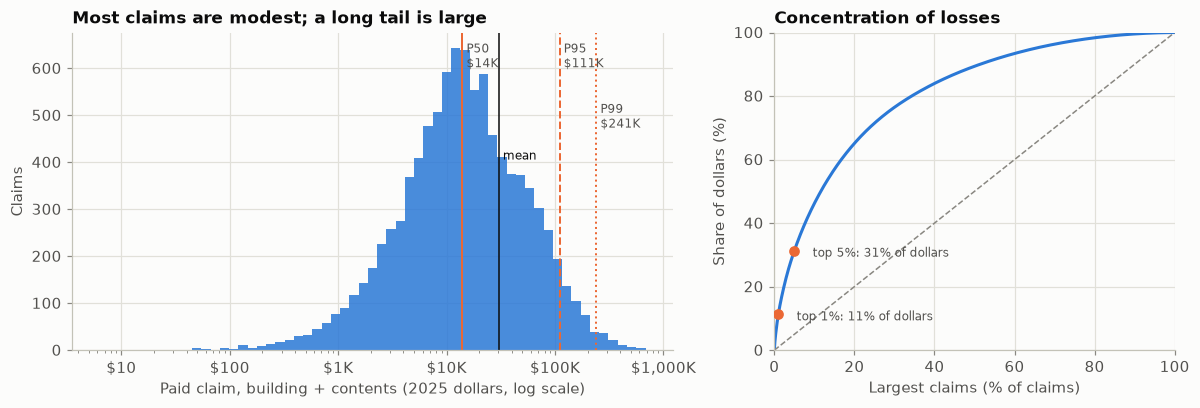

In [3]:
y = d[sv.TARGET].to_numpy()
pct = [10, 25, 50, 75, 90, 95, 99, 99.5, 99.9]
dist = pd.Series({f"P{p:g}": np.percentile(y, p) for p in pct})
dist["max"], dist["mean"] = y.max(), y.mean()
print("Severity (building + contents, 2025 $):")
print(dist.map(lambda v: f"${v:,.0f}").to_string())
print(f"mean / median = {y.mean() / np.median(y):.2f};  skewness = {stats.skew(y):.2f} (0 = symmetric)")
print(f"coefficient of variation (sd / mean) = {y.std() / y.mean():.2f}")
ys = np.sort(y)[::-1]
share = {k: ys[: int(round(k * len(y)))].sum() / y.sum() for k in [0.01, 0.05, 0.10]}
for k, s in share.items():
    print(f"largest {k:.0%} of claims ({int(round(k * len(y)))} claims) = {s:.1%} of dollars")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
bins = np.logspace(np.log10(max(y.min(), 5)), np.log10(y.max()), 60)
a1.hist(y, bins=bins, color=BLUE, alpha=0.85)
a1.set_xscale("log")
a1.xaxis.set_major_formatter(mticker.FuncFormatter(dollars))
for p, ls, h in [(50, "-", 0.97), (95, "--", 0.97), (99, ":", 0.78)]:
    v = np.percentile(y, p)
    a1.axvline(v, color=ORANGE, ls=ls, lw=1.3)
    a1.text(v, a1.get_ylim()[1] * h, f" P{p}\n {dollars(v)}", color=INK_2, fontsize=8, va="top")
a1.axvline(y.mean(), color=INK, lw=1)
a1.text(y.mean(), a1.get_ylim()[1] * 0.6, " mean", fontsize=8, color=INK)
a1.set(xlabel="Paid claim, building + contents (2025 dollars, log scale)", ylabel="Claims",
       title="Most claims are modest; a long tail is large")
xs = np.arange(1, len(ys) + 1) / len(ys)
a2.plot(100 * xs, 100 * np.cumsum(ys) / ys.sum(), color=BLUE, lw=2)
a2.plot([0, 100], [0, 100], color=MUTED, ls="--", lw=1)
for k in [0.01, 0.05]:
    a2.scatter([100 * k], [100 * share[k]], color=ORANGE, zorder=3)
    a2.annotate(f"top {k:.0%}: {share[k]:.0%} of dollars", (100 * k, 100 * share[k]), xytext=(12, -4),
                textcoords="offset points", fontsize=8, color=INK_2)
a2.set(xlabel="Largest claims (% of claims)", ylabel="Share of dollars (%)", xlim=(0, 100), ylim=(0, 100),
       title="Concentration of losses")
fig.tight_layout()
save(fig, "severity_distribution")

**Policy limits.** An NFIP policy pays at most its coverage limit: building coverage up to 250,000 dollars for homes (500,000 for non-residential and per-unit for condo associations), contents up to 100,000 (500,000 non-residential). A claim "hits the limit" here if it paid at least 99% of the limit purchased (limits are nominal, so this is checked in nominal dollars). A claim at the limit is **censored**: the true damage was at least that big, but we only see the limit.

                         claims  building at limit  contents at limit  either  either (% of claims)
occupancy_group                                                                                    
multi-unit residential      799                  9                  9      18                  2.25
non-residential             492                 24                  6      29                  5.89
single-unit residential    8262                 52                 89     131                  1.59
all claims                 9553                 85                104     178                  1.86

Claims at a limit: 178 (1.9%) holding 7.2% of dollars
Building limit hit at the 250K statutory maximum: 16; at a lower limit the owner chose: 69
Largest claims by limit: P99 claim $241,051; share of the 96 largest claims at a limit: 23%
Claims whose building payment exceeds the building limit on the claim record: 12 (likely a mid-term coverage change or condo-unit recording; shown as the last bar

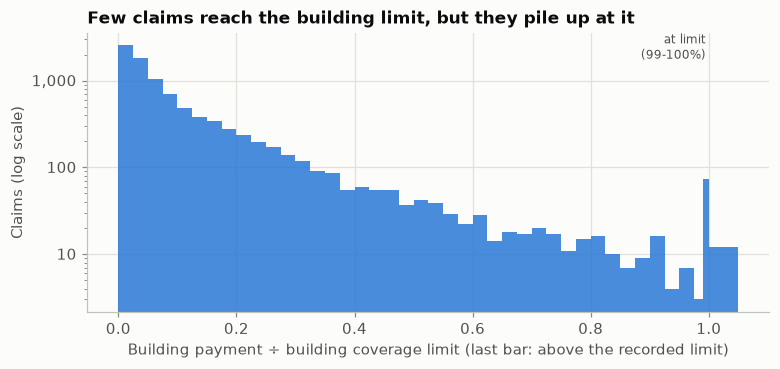

In [4]:
lim = pd.DataFrame({
    "claims": d.groupby("occupancy_group").size(),
    "building at limit": d.groupby("occupancy_group")["building_at_limit"].sum(),
    "contents at limit": d.groupby("occupancy_group")["contents_at_limit"].sum(),
    "either": d.groupby("occupancy_group")["any_limit_hit"].sum()})
lim.loc["all claims"] = lim.sum()
lim["either (% of claims)"] = (100 * lim["either"] / lim["claims"]).round(2)
print(lim.to_string())
at = d["any_limit_hit"]
print(f"\nClaims at a limit: {at.sum()} ({at.mean():.1%}) holding {d.loc[at, sv.TARGET].sum() / y.sum():.1%} of dollars")
print(f"Building limit hit at the 250K statutory maximum: {(d['building_at_limit'] & (d['building_limit'] >= 250_000)).sum()};"
      f" at a lower limit the owner chose: {(d['building_at_limit'] & (d['building_limit'] < 250_000)).sum()}")
print(f"Largest claims by limit: P99 claim ${np.percentile(y, 99):,.0f}; share of the 96 largest claims at a limit: "
      f"{d.loc[d[sv.TARGET].rank(ascending=False) <= 96, 'any_limit_hit'].mean():.0%}")

r = d.loc[d["building_limit"] > 0, "paid_building"] / d.loc[d["building_limit"] > 0, "building_limit"]
print(f"Claims whose building payment exceeds the building limit on the claim record: {(r > 1.0001).sum()} "
      "(likely a mid-term coverage change or condo-unit recording; shown as the last bar)")
fig, ax = plt.subplots(figsize=(8, 3.3))
edges = np.r_[np.linspace(0, 0.975, 40), 0.99, 1.0001, 1.05]
ax.hist(r.clip(0, 1.04), bins=edges, color=BLUE, alpha=0.85)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))
ax.text(0.995, ax.get_ylim()[1] * 0.5, "at limit\n(99-100%)", ha="right", fontsize=8, color=INK_2)
ax.set(xlabel="Building payment ÷ building coverage limit (last bar: above the recorded limit)", ylabel="Claims (log scale)",
       title="Few claims reach the building limit, but they pile up at it")
save(fig, "policy_limits")

## 3. (b) Large losses: cap or not?
**Capping** ("limiting") means fitting the model to claims cut off at a threshold: every claim above the cap counts as exactly the cap. The idea: a handful of huge claims can swing a relativity by chance, and capping makes the factors more stable. The dollars removed are put back with a **large-loss load**, a flat multiplier:

> load = total losses ÷ total capped losses, so predicted severity = capped-model prediction × load.

The cost of capping: the load is **flat**. Classes that really do produce more large claims (big multi-unit and commercial buildings) get less than their share back, and small homes get more. We compare no cap, a cap at the 99th percentile and one at the 95th, all on the 7 core shortlist features, using development years only (each cap is set from the training years of each fold).

In [5]:
CORE = ["occupancy_group", "elevated", "primary_residence", "construction_band",
        "building_coverage_band", "flood_zone_group", "floors_group"]
cap_rows, cap_rels = [], {}
for name, q in [("no cap", None), ("cap at P99", 0.99), ("cap at P95", 0.95)]:
    m = sv.fit_gamma(dev, CORE, cap_quantile=q, **FIT)
    mc = sv.fit_gamma(dev, CORE, cap_quantile=q, cov="cluster", **FIT)
    sc, _ = sv.loyo_scores(dev, lambda tr: sv.fit_gamma(tr, CORE, cap_quantile=q, **FIT), val.DEV_YEARS)
    fold_rels = pd.DataFrame([sv.fit_gamma(tr, CORE, cap_quantile=q, **FIT).relativities()
                              for _, tr, _ in val.leave_one_year_out(dev)])
    rel_cols = list(m.relativities().index)
    se = pd.Series(np.sqrt(np.diag(mc.result.cov_params())), index=m.params.index)[rel_cols]
    cap_rels[name] = m.relativities()
    cap_rows.append({"approach": name, "cap ($)": m.cap, "claims capped": int((dev[sv.TARGET] > m.cap).sum()) if m.cap else 0,
                     "load": m.load, "phi": m.phi,
                     "devLOYO improvement %": sc["improvement_rebased_pct"].mean(),
                     "non-cat folds %": sc.loc[~sc["cat_year"], "improvement_rebased_pct"].mean(),
                     "mean Gini": sc["gini"].mean(),
                     "mean storm-aware SE (log scale)": se.mean(),
                     "fold-to-fold SD of log relativities": np.log(fold_rels).std().mean()})
cap_tbl = pd.DataFrame(cap_rows).set_index("approach")
print(cap_tbl.round(4).to_string())
rel_cmp = pd.DataFrame(cap_rels)
print("\nRelativities under each approach (development years):")
print(rel_cmp.round(3).to_string())

                cap ($)  claims capped    load     phi  devLOYO improvement %  non-cat folds %  mean Gini  mean storm-aware SE (log scale)  fold-to-fold SD of log relativities
approach                                                                                                                                                                       
no cap              NaN              0  1.0000  1.5201                19.1565          22.7287     0.3210                           0.0768                               0.0398
cap at P99  234105.5445             89  1.0317  1.4444                18.7026          22.0120     0.3195                           0.0747                               0.0405
cap at P95  110536.7368            443  1.1423  1.1193                17.5330          20.3421     0.3201                           0.0651                               0.0376

Relativities under each approach (development years):
                                            no cap  cap at P99  c

                         excess share at P99 (% of own dollars)  excess share at P95 (% of own dollars)
occupancy_group                                                                                        
multi-unit residential                                      4.8                                    29.1
non-residential                                            17.9                                    39.2
single-unit residential                                     0.3                                     4.6

All-years caps: P99 = $241,051, P95 = $110,537; loads 1.034 / 1.151
year       2010   2011   2012   2013   2014   2015   2016   2017   2018   2019   2020  2021   2022   2023   2024   2025
P99 load  1.000  1.008  1.013  1.039  1.063  1.004  1.020  1.045  1.088  1.089  1.110   1.0  1.000  1.000  1.093  1.209
P95 load  1.027  1.061  1.142  1.151  1.497  1.118  1.115  1.310  1.281  1.298  1.297   1.0  1.037  1.081  1.320  1.480


saved reports\figures\06_large_losses.png


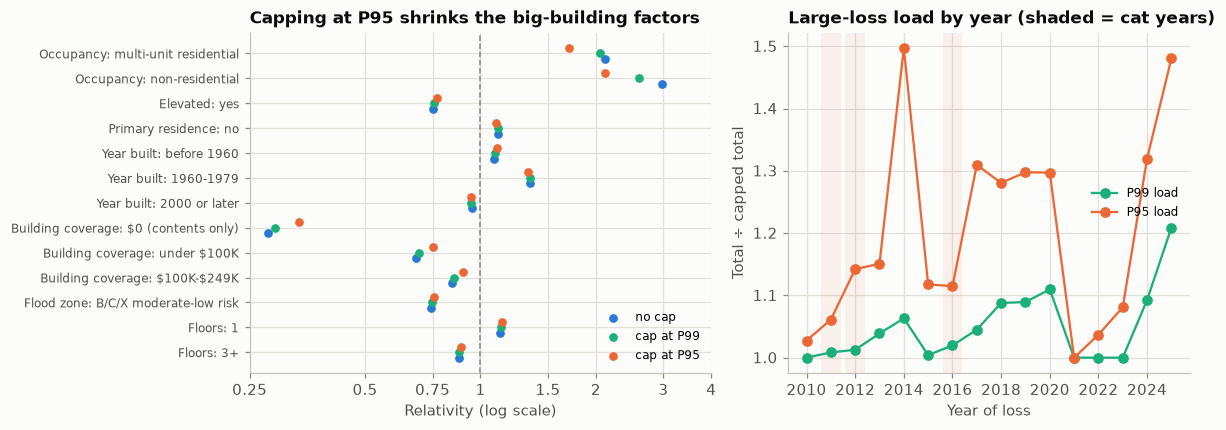

In [6]:
# The load is flat, but large claims are not spread evenly: share of capped-off dollars by occupancy.
cap99 = np.quantile(d[sv.TARGET], 0.99)
cap95 = np.quantile(d[sv.TARGET], 0.95)
excess = d.assign(x99=(d[sv.TARGET] - cap99).clip(lower=0), x95=(d[sv.TARGET] - cap95).clip(lower=0))
g = excess.groupby("occupancy_group")[[sv.TARGET, "x99", "x95"]].sum()
g["excess share at P99 (% of own dollars)"] = 100 * g["x99"] / g[sv.TARGET]
g["excess share at P95 (% of own dollars)"] = 100 * g["x95"] / g[sv.TARGET]
print(g.iloc[:, 3:].round(1).to_string())

loads = pd.DataFrame({f"P{int(100 * q)} load": d.groupby("year")[sv.TARGET].apply(lambda s, c=c: sv.large_loss_load(s, c))
                      for q, c in [(0.99, cap99), (0.95, cap95)]})
print(f"\nAll-years caps: P99 = ${cap99:,.0f}, P95 = ${cap95:,.0f}; loads {sv.large_loss_load(d[sv.TARGET], cap99):.3f} / {sv.large_loss_load(d[sv.TARGET], cap95):.3f}")
print(loads.round(3).T.to_string())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.15, 1]})
order = rel_cmp.index[::-1]
yy = np.arange(len(order))
for k, (name, col) in enumerate([("no cap", BLUE), ("cap at P99", AQUA), ("cap at P95", ORANGE)]):
    a1.scatter(rel_cmp.loc[order, name], yy + (k - 1) * 0.22, color=col, s=22, label=name, zorder=3)
def nice(col):
    f, l = col.split("[", 1)
    l = l.rstrip("]")
    return f"{LABELS[f]}: " + {"True": "yes", "False": "no"}.get(l, l)
a1.set_yticks(yy, [nice(c) for c in order], fontsize=8)
log_rel_axis(a1, 0.25, 4)
a1.set(title="Capping at P95 shrinks the big-building factors", xlabel="Relativity (log scale)")
a1.legend(loc="lower right", fontsize=8)
for name, col in [("P99 load", AQUA), ("P95 load", ORANGE)]:
    a2.plot(loads.index, loads[name], marker="o", color=col, label=name)
for yr in val.CAT_YEARS:
    a2.axvspan(yr - 0.4, yr + 0.4, color=ORANGE, alpha=0.08, lw=0)
a2.set(title="Large-loss load by year (shaded = cat years)", ylabel="Total ÷ capped total", xlabel="Year of loss")
a2.legend(fontsize=8)
fig.tight_layout()
save(fig, "large_losses")

**Recommendation: model the uncapped amounts** (no cap, no load) for the GLM, and keep the P99 cap as a documented sensitivity check.
- **Uncapped validates best on unseen years** (19.2% vs 18.7% at P99 and 17.5% at P95). Capping at P99 does **not** make the relativities more stable: the fold-to-fold spread and storm-aware standard errors are essentially unchanged. P95 narrows them only slightly, and it gets there by changing the answer (next point).
- **NFIP limits already cap the tail.** The largest building payment is bounded by the coverage limit, so the extreme claims that justify capping in, say, commercial property insurance can't happen. The Gamma's deviance also judges claims by **ratio** (actual ÷ predicted), so one huge claim weighs far less than it would in a least-squares fit.
- **Capping at P95 distorts the factors.** A flat load gives back the capped dollars evenly. But large claims are concentrated in multi-unit and non-residential buildings, so the cap pulls their relativities toward 1 (multi-unit 2.1 → 1.7) and overprices single-family homes.
- **If a cap is used later** (for example in XGBoost, which is more sensitive to outliers), P99 is the safe choice: it changes the relativities by under 15%, and its load is about 1.03 overall. The load swings by year (from 1.00 to about 1.2), which is why it must be averaged over many years.

## 4. (c) Building the model step by step (development years 2010–2020 only)
**The keep rule is the same as for frequency, stated before running:** a candidate stays only if (1) a **cluster-robust Wald test** gives p < 0.05, and (2) it improves **leave-one-year-out** (LOYO) re-based Gamma deviance on 2010–2020. The Wald test lets claims in the same county group and year share a surprise, as they do in a storm. For reference, each step also shows the classic in-sample measures:
- **Deviance** (how far the fitted values are from the data, Gamma version) and its drop.
- **AIC** = −2 × log-likelihood + 2 × parameters; lower is better.
- **F-test**: the deviance drop per added parameter ÷ the dispersion φ. It's the standard GLM test when, as for the Gamma, the spread is estimated; it is the likelihood-ratio test adjusted for that.

The order follows the Milestone 6 severity shortlist (strongest one-way factor first): **occupancy** to start, then elevated, primary residence, year built, coverage band, flood zone, floors, (optional) post-FIRM. Then **geography**: (A) Tidewater, the recommended coastal definition; (B) + the Census coastal flag; (C) county group in place of the flags.

In [7]:
order = ["elevated", "primary_residence", "construction_band", "building_coverage_band",
         "flood_zone_group", "floors_group", "post_firm"]
cands = [{"name": f"+ {LABELS[f].lower()}", "add": [f]} for f in order]
cands += [{"name": "Geography A: + Tidewater", "add": ["coastal_tidal"]},
          {"name": "Geography B: + Census coastal", "add": ["coastal"]},
          {"name": "Geography C: county group (replaces flags)", "add": ["county_group"], "remove": ["coastal_tidal", "coastal"]}]
steps, feats1 = sv.forward_selection(dev, ["occupancy_group"], cands, val.DEV_YEARS, fit_kw=FIT)
show = ["decision", "n_params", "d_deviance", "d_AIC", "F_p", "LRT_p", "cluster_Wald_p",
        "devLOYO_improvement_pct", "d_devLOYO_pct", "devLOYO_folds_better"]
t = steps[show].copy()
for c in ["F_p", "LRT_p", "cluster_Wald_p"]:
    t[c] = t[c].map(fmt_p)
print(t.round(2).to_string())
print("\nAfter the forward pass:", feats1)
print(f"AIC would keep {int((steps['d_AIC'].iloc[1:] < 0).sum())} of {len(cands)} candidates; the F-test {int((steps['F_p'].iloc[1:] < 0.05).sum())}.")

                                                                                               decision  n_params  d_deviance    d_AIC      F_p    LRT_p cluster_Wald_p  devLOYO_improvement_pct  d_devLOYO_pct devLOYO_folds_better
step                                                                                                                                                                                                                                
start: occupancy_group                                                                            start        13     1442.31 -1224.93  <0.0001  <0.0001        <0.0001                    15.12          15.12                10/11
+ elevated                                                                  drop: worse on unseen years        14      134.76  -119.68  <0.0001  <0.0001         0.0067                    14.90          -0.21                 5/11
+ primary residence                                                drop: not signifi

**Order matters.** Forward selection tests each candidate only once, against whatever is in the model at that moment. *Elevated* was tested second, when the model held only occupancy. That's before flood zone and year built, which elevated overlaps with (elevated buildings sit in A/V zones and are newer). So a **second pass** re-tests every dropped feature against the forward-pass model, with the same rule. Of those that pass, the one with the biggest unseen-year gain is added, and the rest are tested again, until nothing passes.

*Honesty note:* the second pass was added after a dry run showed this order effect. The keep rule itself is unchanged. The frequency model was built with a forward pass only. Re-checking it the same way is noted as a follow-up for the model-comparison milestone.

In [8]:
dropped = [f for f in order + ["coastal_tidal"] if f not in feats1]
second, FINAL = sv.second_pass(dev, feats1, dropped, val.DEV_YEARS, fit_kw=FIT)
t2 = second[["round", "candidate", "passes", "added", "d_deviance", "cluster_Wald_p", "d_devLOYO_pct", "devLOYO_folds_better"]].copy()
t2["cluster_Wald_p"] = t2["cluster_Wald_p"].map(fmt_p)
print(t2.round(3).to_string(index=False))
print("\nFINAL severity features:", FINAL)
geo_in = [f for f in FINAL if f in ("coastal_tidal", "coastal", "county_group")]
print("Geography in the final model:", geo_in or "none")

 round         candidate  passes  added  d_deviance cluster_Wald_p  d_devLOYO_pct devLOYO_folds_better
     1          elevated    True  False     136.263         0.0005          0.208                 6/11
     1 primary_residence    True   True      17.345         0.0472          0.280                 9/11
     1         post_firm   False  False      16.659         0.0589         -0.056                 4/11
     1     coastal_tidal   False  False      22.356         0.0840          0.458                 6/11
     2          elevated    True   True     133.364         0.0007          0.182                 6/11
     2         post_firm   False  False      17.451         0.0547         -0.042                 4/11
     2     coastal_tidal   False  False      22.554         0.0793          0.453                 6/11
     3         post_firm   False  False      20.980         0.0283         -0.031                 4/11
     3     coastal_tidal   False  False      16.036         0.1418       

saved reports\figures\06_model_build_steps.png


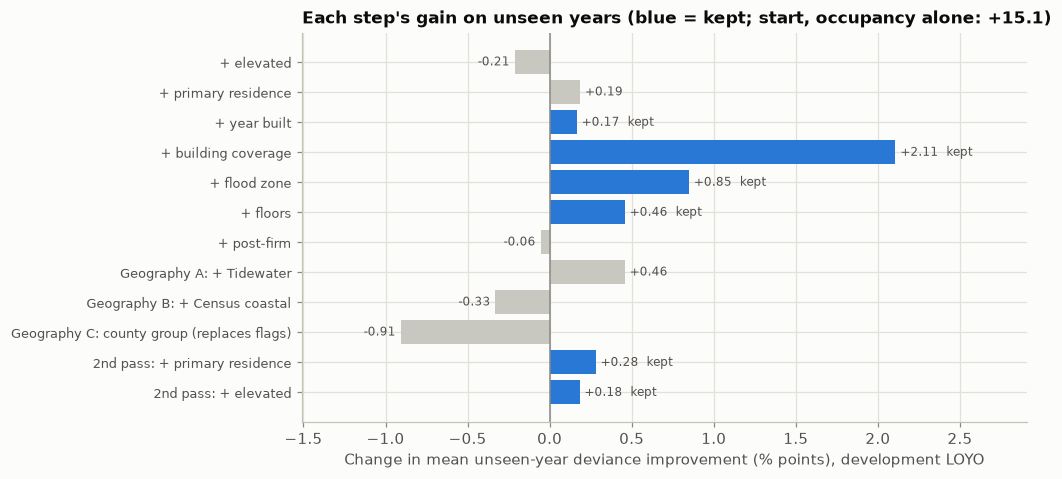

In [9]:
# Chart: unseen-year gain of every step (forward pass, then second-pass additions).
plot = steps.iloc[1:][["d_devLOYO_pct", "decision"]].copy()
plot["kept"] = plot["decision"].eq("KEEP")
add2 = second[second["added"]]
for _, r in add2.iterrows():
    plot.loc[f"2nd pass: + {LABELS[r['candidate']].lower()}"] = [r["d_devLOYO_pct"], "KEEP", True]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
yy = np.arange(len(plot))[::-1]
ax.barh(yy, plot["d_devLOYO_pct"], color=[BLUE if k else "#c9c8c0" for k in plot["kept"]])
ax.set_yticks(yy, plot.index, fontsize=8.5)
ax.axvline(0, color=MUTED, lw=1)
for yv, (v, k) in zip(yy, plot[["d_devLOYO_pct", "kept"]].to_numpy()):
    ax.text(v + (0.03 if v >= 0 else -0.03), yv, f"{v:+.2f}" + ("  kept" if k else ""), va="center",
            ha="left" if v >= 0 else "right", fontsize=8, color=INK_2)
ax.set(xlabel="Change in mean unseen-year deviance improvement (% points), development LOYO",
       title=f"Each step's gain on unseen years (blue = kept; start, occupancy alone: +{steps['d_devLOYO_pct'].iloc[0]:.1f})")
ax.set_xlim(min(-1.3, plot["d_devLOYO_pct"].min() - 0.6), max(2.8, plot["d_devLOYO_pct"].max() + 0.8))
save(fig, "model_build_steps")

**ICC sensitivity.** Would including ICC in the modelled amount change the answer? Refit the final features on building + contents + ICC (ICC-only claims included):

In [10]:
d_icc = claims_all.assign(amount_icc=claims_all["total_2025"])
d_icc = d_icc[d_icc["amount_icc"] > 0].reset_index(drop=True)
r_ex = sv.fit_gamma(d, FINAL, **FIT).relativities()
r_in = sv.fit_gamma(d_icc, FINAL, target="amount_icc", **FIT).relativities()
icc_cmp = pd.DataFrame({"without ICC (chosen)": r_ex, "with ICC": r_in})
icc_cmp["ratio"] = icc_cmp["with ICC"] / icc_cmp["without ICC (chosen)"]
print(icc_cmp.round(3).to_string())
print(f"largest change: {100 * (icc_cmp['ratio'] - 1).abs().max():.1f}%")

                                            without ICC (chosen)  with ICC  ratio
occupancy_group[multi-unit residential]                    2.098     2.082  0.992
occupancy_group[non-residential]                           3.067     3.028  0.987
construction_band[before 1960]                             1.022     1.021  0.999
construction_band[1960-1979]                               1.282     1.285  1.002
construction_band[2000 or later]                           0.897     0.968  1.080
building_coverage_band[$0 (contents only)]                 0.280     0.278  0.994
building_coverage_band[under $100K]                        0.692     0.693  1.002
building_coverage_band[$100K-$249K]                        0.853     0.856  1.004
flood_zone_group[B/C/X moderate-low risk]                  0.746     0.737  0.988
floors_group[1]                                            1.123     1.137  1.013
floors_group[3+]                                           0.891     0.891  0.999
primary_residenc

## 5. (d) The final severity model (refitted on all 16 years)
Selection used 2010–2020 only. The relativity table comes from a refit on all 16 years (the same practice as for frequency), with **storm-aware (cluster-robust, county group × year) 95% CIs** recommended and plain Gamma CIs for reference. The **base levels** are the frequency model's: A/V zone, single-unit residential, built 1980–1999, 250K+ building coverage, 2 floors, not elevated, primary residence.

In [11]:
final = sv.fit_gamma(d, FINAL, **FIT)
final_cl = sv.fit_gamma(d, FINAL, cov="cluster", **FIT)
assert np.allclose(final.params, final_cl.params)
rel = sv.relativity_table(final, d, {"gamma": final.result, "cluster": final_cl.result})
rel["feature_label"] = rel["feature"].map(LABELS)
BASE_SEV = float(np.exp(final.params["const"] + final.avg_year_log))
print(f"Base claim size (average year, all base levels): ${BASE_SEV:,.0f}")
print(f"Gamma dispersion phi = {final.phi:.3f} (coefficient of variation of a claim around its prediction about {np.sqrt(final.phi):.2f})")
print(f"Clusters (county group x year): {len(np.unique(fg.cluster_codes(d, ('county_group', 'year'))))}")
w_g = (rel["hi_gamma"] / rel["lo_gamma"]).where(~rel["is_base"])
w_c = (rel["hi_cluster"] / rel["lo_cluster"]).where(~rel["is_base"])
print(f"Average CI width (log scale), cluster vs plain Gamma: {(np.log(w_c) / np.log(w_g)).mean():.2f}x")
out = rel[["feature_label", "level", "is_base", "claims", "actual_avg_severity", "relativity", "lo_cluster", "hi_cluster", "lo_gamma", "hi_gamma"]]
print(out.round(3).to_string(index=False))

Base claim size (average year, all base levels): $28,498
Gamma dispersion phi = 1.528 (coefficient of variation of a claim around its prediction about 1.24)
Clusters (county group x year): 372
Average CI width (log scale), cluster vs plain Gamma: 1.74x
    feature_label                   level  is_base  claims  actual_avg_severity  relativity  lo_cluster  hi_cluster  lo_gamma  hi_gamma
        Occupancy single-unit residential     True    8262            24768.688       1.000       1.000       1.000     1.000     1.000
        Occupancy  multi-unit residential    False     799            58782.477       2.098       1.656       2.658     1.895     2.323
        Occupancy         non-residential    False     492            77799.407       3.067       2.569       3.661     2.700     3.484
       Year built               1980-1999     True    1567            26917.188       1.000       1.000       1.000     1.000     1.000
       Year built             before 1960    False    3196         

Year factor vs average year: {2010: 0.57, 2011: 0.8, 2012: 0.89, 2013: 0.56, 2014: 0.68, 2015: 0.7, 2016: 1.4, 2017: 0.6, 2018: 1.05, 2019: 1.31, 2020: 0.8, 2021: 0.79, 2022: 0.69, 2023: 0.6, 2024: 1.46, 2025: 0.98}
saved reports\figures\06_severity_relativities.png


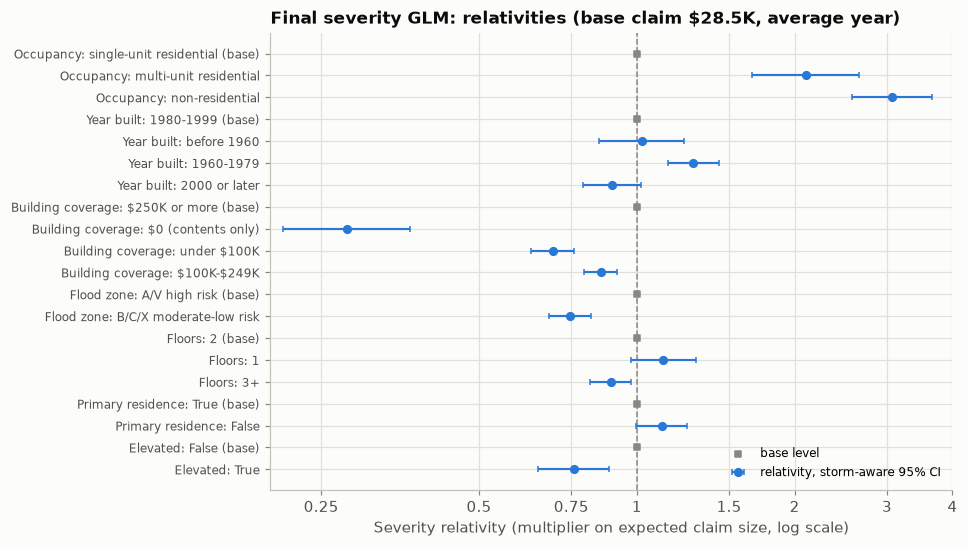

In [12]:
# Year effects relative to the average year (what the year factor absorbs).
yr = pd.Series({int(l): float(np.exp(final.params.get(f"year[{l}]", 0.0) + final.params["const"]) / BASE_SEV)
                for l in final.spec.levels["year"]}).sort_index()
print("Year factor vs average year:", yr.round(2).to_dict())

fig, ax = plt.subplots(figsize=(8, 5.4))
r = rel.copy()
r["label"] = r["feature_label"] + ": " + r["level"] + np.where(r["is_base"], " (base)", "")
yy = np.arange(len(r))[::-1]
nb = ~r["is_base"]
ax.errorbar(r.loc[nb, "relativity"], yy[nb.to_numpy()],
            xerr=[r.loc[nb, "relativity"] - r.loc[nb, "lo_cluster"], r.loc[nb, "hi_cluster"] - r.loc[nb, "relativity"]],
            fmt="o", color=BLUE, ecolor=BLUE, elinewidth=1.4, capsize=2, ms=5, label="relativity, storm-aware 95% CI")
ax.scatter(r.loc[r["is_base"], "relativity"], yy[r["is_base"].to_numpy()], marker="s", color=MUTED, s=18, zorder=3, label="base level")
ax.set_yticks(yy, r["label"], fontsize=8)
log_rel_axis(ax, 0.2, 4)
ax.set(xlabel="Severity relativity (multiplier on expected claim size, log scale)",
       title=f"Final severity GLM: relativities (base claim ${BASE_SEV / 1000:,.1f}K, average year)")
ax.legend(loc="lower right", fontsize=8)
save(fig, "severity_relativities")

## 6. (e) Frequency and severity side by side
For each factor: the **frequency** relativity (notebook 05's final model; for factors it dropped, the 9-feature "full" frequency GLM shown in grey), the **severity** relativity (this model; for factors it dropped, a model with the factor added), and their product, the **pure-premium** relativity (how the factor moves expected loss cost).

**Classification rule:** a factor *drives* frequency (or severity) if it is in that final model **and** at least one level moves the relativity by 10% or more (outside 0.91–1.10).

In [13]:
fr = pd.read_csv(ROOT / "reports" / "04_frequency_relativities.csv", dtype={"level": str})
fv = pd.read_csv(ROOT / "reports" / "04_oneway_vs_glm.csv", dtype={"level": str})
freq_final = set(json.loads((ROOT / "models" / "frequency_glm.json").read_text())["spec"]["features"])
# Severity relativity for factors not in the final model: fit with the factor added (all years).
sev_extra = {}
for f in [f for f in CORE + ["post_firm", "coastal_tidal"] if f not in FINAL]:
    sev_extra.update(sv.fit_gamma(d, FINAL + [f], **FIT).relativities().to_dict())
rows = []
for _, r in fv.iterrows():
    f, l = r["feature"], str(r["level"])
    col = f"{f}[{l}]"
    in_f, in_s = f in freq_final, f in FINAL
    f_rel = r["final_glm"] if in_f else r["full_glm"]
    s_rel = 1.0 if r["base"] else (final.relativities().get(col) if in_s else sev_extra.get(col, np.nan))
    if r["base"]:
        s_rel = 1.0
    rows.append({"feature": f, "label": LABELS[f], "level": l, "is_base": bool(r["base"]),
                 "freq_rel": f_rel, "freq_in_final": in_f, "sev_rel": s_rel, "sev_in_final": in_s,
                 "pure_premium_rel": f_rel * s_rel})
fs = pd.DataFrame(rows)

def drives(sub, rel_col, in_col):
    return bool(sub[in_col].iloc[0]) and ((sub[rel_col] < 1 / 1.1) | (sub[rel_col] > 1.1)).any()
cls = []
for f, sub in fs.groupby("feature", sort=False):
    df_, ds_ = drives(sub, "freq_rel", "freq_in_final"), drives(sub, "sev_rel", "sev_in_final")
    cls.append({"feature": LABELS[f], "drives frequency": df_, "drives severity": ds_,
                "class": {(True, True): "both", (True, False): "frequency only",
                          (False, True): "severity only", (False, False): "neither"}[(df_, ds_)]})
cls = pd.DataFrame(cls)
print(fs.round(3).to_string(index=False))
print()
print(cls.to_string(index=False))

               feature             label                   level  is_base  freq_rel  freq_in_final  sev_rel  sev_in_final  pure_premium_rel
      flood_zone_group        Flood zone           A/V high risk     True     1.000           True    1.000          True             1.000
      flood_zone_group        Flood zone B/C/X moderate-low risk    False     0.458           True    0.746          True             0.341
     construction_band        Year built               1980-1999     True     1.000           True    1.000          True             1.000
     construction_band        Year built             before 1960    False     2.728           True    1.022          True             2.788
     construction_band        Year built               1960-1979    False     2.748           True    1.282          True             3.523
     construction_band        Year built           2000 or later    False     0.643           True    0.897          True             0.576
building_coverage_ba

saved reports\figures\06_frequency_vs_severity.png


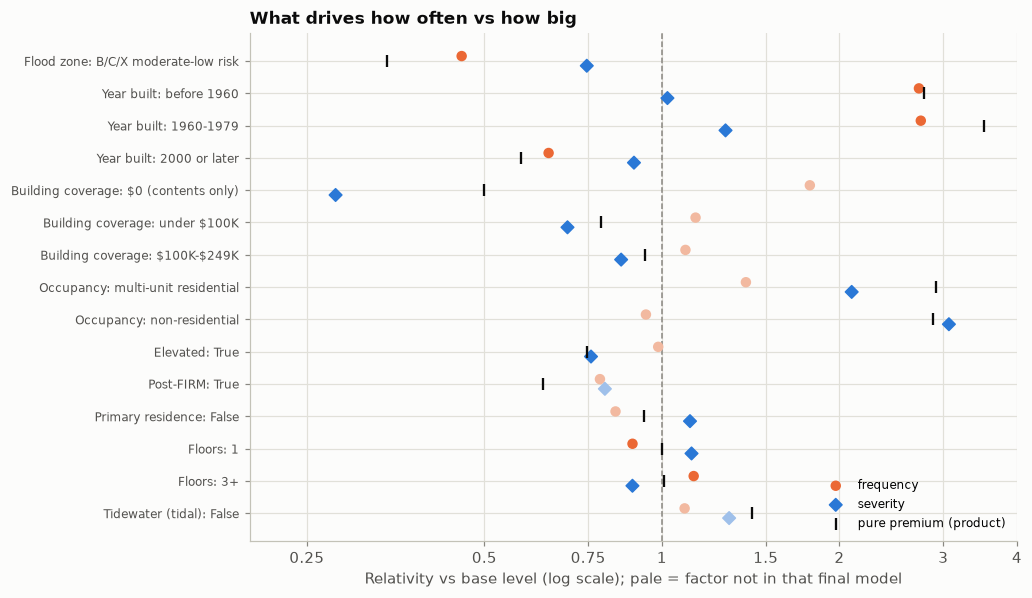

In [14]:
nb_ = fs[~fs["is_base"]].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 6))
yy = np.arange(len(nb_))[::-1]
lab = nb_["label"] + ": " + nb_["level"]
ax.scatter(nb_["freq_rel"], yy + 0.15, s=34, label="frequency", zorder=3,
           color=[ORANGE if k else "#f2b9a0" for k in nb_["freq_in_final"]])
ax.scatter(nb_["sev_rel"], yy - 0.15, s=34, marker="D", label="severity", zorder=3,
           color=[BLUE if k else "#9fc0ea" for k in nb_["sev_in_final"]])
ax.scatter(nb_["pure_premium_rel"], yy, s=60, marker="|", color=INK, label="pure premium (product)", zorder=4)
ax.set_yticks(yy, lab, fontsize=8)
log_rel_axis(ax, 0.2, 4)
ax.set(xlabel="Relativity vs base level (log scale); pale = factor not in that final model",
       title="What drives how often vs how big")
ax.legend(loc="lower right", fontsize=8)
save(fig, "frequency_vs_severity")

## 7. (f) Does the model fit? Residuals and Gamma vs lognormal
A **residual** is what's left after the model: actual − predicted, on some scale. If the model is right, residuals show **no pattern** against the fitted values or the features.
- **Deviance residuals**: each claim's signed contribution to the deviance, on a scale where a perfect fit gives 0.
- **Quantile residuals**: put each claim through its fitted Gamma distribution (what percentile of its own predicted distribution is it?) and convert that to a normal z-score. If the Gamma shape is right, these look like a standard normal sample, so a Q–Q plot against the normal checks the whole distribution, including the tail.

**Lognormal alternative:** model log(claim) with ordinary least squares. It's also right-skewed. But its *mean* is exp(Xβ + σ²/2), not exp(Xβ). Forgetting that back-transform under-predicts, and the normal-theory correction can over-correct when the spread differs between groups.

In [15]:
mg = sv.fit_gamma(dev, FINAL, **FIT)
ln = sv.fit_lognormal(dev, FINAL)
mu_g = mg.predict(dev, "fitted")
ll_g, k_g = sv.gamma_loglik_ml(dev[sv.TARGET], mu_g)
fit_cmp = pd.DataFrame({
    "AIC (dollar scale)": [sv.aic_gamma(mg, dev), sv.aic_lognormal(ln, dev)],
    "parameters": [len(mg.params) + 1, len(ln.params) + 1]}, index=["Gamma GLM", "lognormal"])
print(fit_cmp.round(1).to_string())
print(f"Gamma shape k = {k_g:.3f} (ML); lognormal sigma = {np.sqrt(ln.sigma2):.3f}")
actual = dev[sv.TARGET].sum()
bt = pd.Series({c: ln.predict(dev, "fitted", c).sum() / actual for c in ["none", "normal", "smearing"]},
               name="lognormal predicted total / actual (training)")
bt["Gamma GLM"] = mu_g.sum() / actual
print(bt.round(3).to_string())

comp = []
for name, fn in [("Gamma GLM", lambda tr: sv.fit_gamma(tr, FINAL, **FIT)),
                 ("lognormal (normal correction)", lambda tr: sv.fit_lognormal(tr, FINAL))]:
    sc, _ = sv.loyo_scores(dev, fn, val.DEV_YEARS)
    comp.append({"model": name, "devLOYO improvement %": sc["improvement_rebased_pct"].mean(),
                 "folds better than null": int((sc["improvement_rebased_pct"] > 0).sum()),
                 "mean A/E": sc["actual_over_expected"].mean(), "mean Gini": sc["gini"].mean()})
print(pd.DataFrame(comp).set_index("model").round(3).to_string())

           AIC (dollar scale)  parameters
Gamma GLM            197754.1          25
lognormal            197885.5          25
Gamma shape k = 0.958 (ML); lognormal sigma = 1.213
none         0.537
normal       1.121
smearing     0.994
Gamma GLM    0.987


                               devLOYO improvement %  folds better than null  mean A/E  mean Gini
model                                                                                            
Gamma GLM                                     19.156                      11     0.936      0.321
lognormal (normal correction)                 17.564                      11     0.907      0.317


saved reports\figures\06_residuals.png
Occupancy            multi-unit residential: -0.081  non-residential: -0.117  single-unit residential: -0.000
Year built           1960-1979: +0.023  1980-1999: -0.039  2000 or later: -0.128  before 1960: -0.029
Building coverage    $0 (contents only): +0.082  $100K-$249K: +0.025  $250K or more: -0.048  under $100K: -0.017
Flood zone           A/V high risk: +0.009  B/C/X moderate-low risk: -0.070
Floors               1: +0.002  2: -0.010  3+: -0.046
Primary residence    False: -0.025  True: -0.008
Elevated             False: -0.008  True: -0.020
Tidewater (tidal)    False: +0.019  True: -0.018


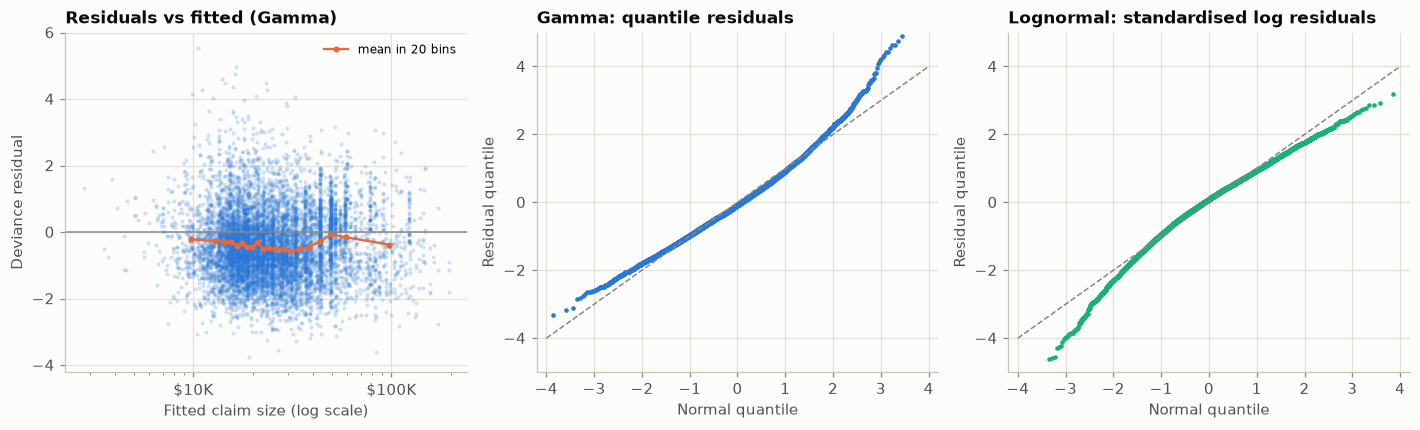

In [16]:
yv = dev[sv.TARGET].to_numpy()
z_g = sv.quantile_residuals(yv, mu_g, k_g)
z_l = (np.log(yv) - ln.eta(dev, True)) / np.sqrt(ln.sigma2)
dres = sv.deviance_residuals(yv, mu_g)
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
# (1) deviance residuals vs fitted, with binned means
ax = axs[0]
ax.scatter(mu_g, dres, s=3, alpha=0.15, color=BLUE, rasterized=True)
bins = pd.qcut(mu_g, 20, duplicates="drop")
bm = pd.DataFrame({"mu": mu_g, "r": dres}).groupby(bins, observed=True).mean()
ax.plot(bm["mu"], bm["r"], color=ORANGE, marker="o", ms=3, label="mean in 20 bins")
ax.axhline(0, color=MUTED, lw=1)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(dollars))
ax.set(xlabel="Fitted claim size (log scale)", ylabel="Deviance residual", title="Residuals vs fitted (Gamma)")
ax.legend(fontsize=8)
# (2) and (3): Q-Q plots
for ax, z, name, col in [(axs[1], z_g, "Gamma: quantile residuals", BLUE), (axs[2], z_l, "Lognormal: standardised log residuals", AQUA)]:
    q = np.sort(z)
    th = stats.norm.ppf((np.arange(1, len(q) + 1) - 0.5) / len(q))
    ax.scatter(th, q, s=4, color=col, rasterized=True)
    ax.plot([-4, 4], [-4, 4], color=MUTED, ls="--", lw=1)
    ax.set(xlim=(-4.2, 4.2), ylim=(-5, 5), xlabel="Normal quantile", ylabel="Residual quantile", title=name)
fig.tight_layout()
save(fig, "residuals")

# Residual means by feature level (should be about 0 for features in the model).
rs = dev.assign(qres=z_g)
for f in FINAL + [x for x in ["elevated", "coastal_tidal"] if x not in FINAL]:
    m_ = rs.groupby(f, observed=True)["qres"].agg(["mean", "size"])
    print(f"{LABELS[f]:<20}", "  ".join(f"{k}: {v:+.3f}" for k, v in m_["mean"].items()))

**Reading the plots.**
- **Residuals vs fitted:** the binned means form a roughly flat line, so there is no systematic over- or under-prediction for small vs large predicted claims. They sit a little below 0, which is normal for Gamma deviance residuals when the data are this skewed (the median claim is below the mean). The vertical stripes are groups of claims with identical features.
- **Gamma Q–Q:** close to the line for the middle ~95% of claims. In the **upper tail** the points rise above the line: the largest ~2% of claims are bigger than a Gamma with one shape parameter expects. At the bottom there are slightly *fewer* tiny claims than it expects.
- **Lognormal Q–Q:** the mirror image. Its upper tail is **too heavy** (it expects bigger extremes than policy limits allow), and it has too few very small claims on the log scale.
- **Why the Gamma is still preferred:** lower AIC on the dollar scale, better on unseen years, and no back-transform needed (the GLM predicts the mean directly; the lognormal's mean is 0.54× actual without a correction and 1.12× with the textbook one). Also, a Gamma GLM's relativities stay valid even if the exact Gamma shape is off, as long as the mean structure is right and the spread grows with the mean. The storm-aware CIs don't rely on the Gamma shape either. The tail misfit matters more for anything that uses the *distribution* (for example, pricing a deductible or reinsurance layer), which is out of scope.

## 8. Held-out evaluation (validation plan)
Following `docs/validation_plan.md`:
- **LOYO over all 16 years** is the headline, with each year counting once, and summaries with and without the three catastrophe years.
- **The 2021–2025 holdout**, trained on 2010–2020, is scored once.

The baseline is the **no-features model**: every claim gets the training-average claim size. *Re-based* means the predictions are scaled to the year's actual average, so the score measures **which claims are bigger**, not the storm year's overall level. Raw A/E shows calibration. As for frequency, the model predicts an **average year**.

In [17]:
sc, oof = sv.loyo_scores(d, lambda tr: sv.fit_gamma(tr, FINAL, **FIT), keep_cols=list(dict.fromkeys(FINAL + ["county_group", "coastal_tidal", "elevated", "primary_residence"])))
assert len(oof) == len(d)
show = ["test_year", "cat_year", "test_claims", "actual_avg", "pred_avg", "actual_over_expected",
        "improvement_rebased_pct", "gini"]
print(sc[show].round(3).to_string(index=False))
summ = pd.concat({m: val.summarize_scores(sc, m).iloc[0] for m in ["improvement_rebased_pct", "gini", "actual_over_expected"]}, axis=1)
print(summ.round(3).to_string())
print(f"Years beating the no-features baseline: {(sc['improvement_rebased_pct'] > 0).sum()} of {len(sc)}")
cw = np.average(sc["improvement_rebased_pct"], weights=sc["test_claims"])
print(f"Claim-weighted mean improvement: {cw:.1f}%")
null_rb = oof.groupby("year")[sv.TARGET].transform("mean")     # re-based null = each year's own average
pooled = 100 * (1 - sv.gamma_deviance(oof[sv.TARGET], oof["pred_rebased"]) / sv.gamma_deviance(oof[sv.TARGET], null_rb))
print(f"Pooled re-based improvement (all out-of-fold claims): {pooled:.1f}%")
print(f"Raw A/E summed over all LOYO years: {oof[sv.TARGET].sum() / oof['pred'].sum():.3f}")

tr_h, te_h = val.time_holdout(d)
mh = sv.fit_gamma(tr_h, FINAL, **FIT)
ho = sv.score_fold(te_h, mh.predict(te_h), sv.null_prediction(tr_h, te_h))
print("\nFINAL HOLDOUT (train 2010-2020, test 2021-2025):", {k: round(v, 3) for k, v in ho.items()})
ho_by_year = sv.actual_vs_expected(te_h, mh.predict(te_h), "year")
print(ho_by_year.round(3).to_string())

 test_year  cat_year  test_claims  actual_avg  pred_avg  actual_over_expected  improvement_rebased_pct  gini
      2010     False          245   15409.630 31255.625                 0.493                    3.491 0.180
      2011      True         2795   21170.646 29693.054                 0.713                    0.829 0.128
      2012      True         1196   27869.279 31970.375                 0.872                   16.412 0.267
      2013     False          228   21267.949 36559.288                 0.582                   29.845 0.385
      2014     False          305   30666.966 30272.998                 1.013                   37.789 0.599
      2015     False          358   19054.638 29695.342                 0.642                    2.078 0.154
      2016      True         2342   44432.182 25113.292                 1.769                   12.076 0.238
      2017     False           82   25525.560 33603.669                 0.760                   43.584 0.535
      2018     Fals


FINAL HOLDOUT (train 2010-2020, test 2021-2025): {'test_claims': 677, 'actual_avg': 31427.588, 'pred_avg': 30849.06, 'null_avg': 30262.159, 'actual_over_expected': 1.019, 'deviance_raw': 1038.169, 'null_deviance_raw': 1246.772, 'deviance_rebased': 1038.319, 'null_deviance_rebased': 1245.793, 'gini': 0.297, 'improvement_rebased_pct': 16.654, 'improvement_raw_pct': 16.731}
      claims       actual     expected  actual_avg_severity  expected_avg_severity  actual_over_expected
year                                                                                                    
2021     151  2607641.177  3750406.514            17269.147              24837.129                 0.695
2022     110  2007050.062  3461586.365            18245.910              31468.967                 0.580
2023      56   992227.833  1662622.244            17718.354              29689.683                 0.597
2024     185  8292825.970  5945215.825            44826.086              32136.302                 1

          feature                   level  claims   A/E  in_model
        Occupancy  multi-unit residential   799.0 1.041      True
        Occupancy         non-residential   492.0 0.922      True
        Occupancy single-unit residential  8262.0 1.007      True
       Year built               1960-1979  4210.0 1.047      True
       Year built               1980-1999  1567.0 0.995      True
       Year built           2000 or later   580.0 0.967      True
       Year built             before 1960  3196.0 0.917      True
Building coverage      $0 (contents only)   199.0 0.872      True
Building coverage             $100K-$249K  3674.0 0.993      True
Building coverage           $250K or more  4386.0 1.049      True
Building coverage             under $100K  1294.0 0.810      True
       Flood zone           A/V high risk  6853.0 1.003      True
       Flood zone B/C/X moderate-low risk  2700.0 0.990      True
           Floors                       1  3030.0 0.995      True
          

saved reports\figures\06_actual_vs_expected.png
County groups with >= 30 claims: 29; A/E outside 0.8-1.25: 9
                                            name  claims  actual_over_expected
county_group                                                                  
51103                           Lancaster County      32                  0.55
51199                                York County      75                  0.57
51179                            Stafford County      36                  0.67
51650                               Hampton city     834                  0.75
51740                            Portsmouth city     425                  0.75
51550                            Chesapeake city     622                  0.77
51153                      Prince William County     137                  0.79
51710                               Norfolk city    1333                  0.79
51760                              Richmond city      38                  0.80
51735                 

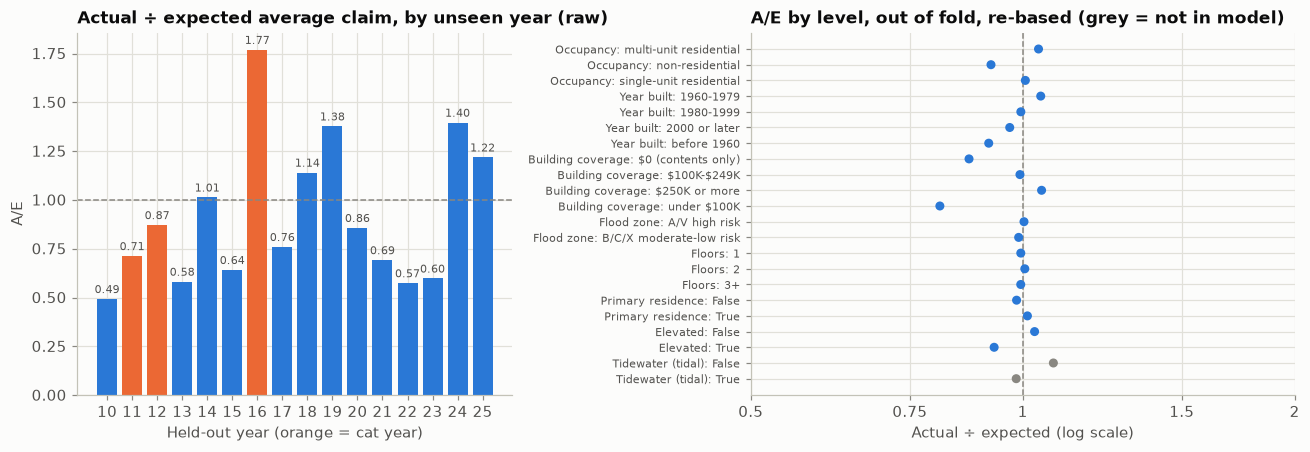

In [18]:
# A/E by year (raw) and by feature (re-based, out of fold)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
cols = [ORANGE if c else BLUE for c in sc["cat_year"]]
a1.bar(sc["test_year"], sc["actual_over_expected"], color=cols)
a1.axhline(1, color=MUTED, ls="--", lw=1)
for x_, v in zip(sc["test_year"], sc["actual_over_expected"]):
    a1.text(x_, v + 0.03, f"{v:.2f}", ha="center", fontsize=7, color=INK_2)
a1.set(title="Actual ÷ expected average claim, by unseen year (raw)", ylabel="A/E", xlabel="Held-out year (orange = cat year)")
a1.set_xticks(sc["test_year"], [str(v)[2:] for v in sc["test_year"]])

ae_rows = []
for f in FINAL + [f for f in ["elevated", "primary_residence", "coastal_tidal"] if f not in FINAL]:
    t_ = sv.actual_vs_expected(oof, oof["pred_rebased"], f)
    for l, r_ in t_.iterrows():
        ae_rows.append({"feature": LABELS[f], "level": str(l), "claims": r_["claims"], "A/E": r_["actual_over_expected"],
                        "in_model": f in FINAL})
ae = pd.DataFrame(ae_rows)
print(ae.round(3).to_string(index=False))
yy = np.arange(len(ae))[::-1]
a2.scatter(ae["A/E"], yy, color=[BLUE if k else MUTED for k in ae["in_model"]], s=24, zorder=3)
a2.set_yticks(yy, ae["feature"] + ": " + ae["level"], fontsize=7.5)
log_rel_axis(a2, 0.5, 2)
a2.set(title="A/E by level, out of fold, re-based (grey = not in model)", xlabel="Actual ÷ expected (log scale)")
fig.tight_layout()
save(fig, "actual_vs_expected")

grp = sv.actual_vs_expected(oof, oof["pred_rebased"], "county_group")
grp = grp[grp["claims"] >= 30]
print(f"County groups with >= 30 claims: {len(grp)}; A/E outside 0.8-1.25: {((grp['actual_over_expected'] < 0.8) | (grp['actual_over_expected'] > 1.25)).sum()}")
names = d.drop_duplicates("county_group").set_index("county_group")["county_name"]
grp["name"] = [names.get(g, g) if str(g).startswith("51") else g for g in grp.index]
print(grp.sort_values("actual_over_expected")[["name", "claims", "actual_over_expected"]].round(2).to_string())

LOYO pooled:
        claims  actual_total   pred_total  actual_avg  pred_avg  actual_relative_to_average
decile                                                                                     
1          956   16499384.67  11499987.79    17258.77  12029.28                        0.57
2          955   15744826.57  14908532.54    16486.73  15611.03                        0.54
3          955   17434137.97  17754699.45    18255.64  18591.31                        0.60
4          956   17771316.33  19230231.63    18589.24  20115.31                        0.61
5          955   23089517.09  23970040.10    24177.50  25099.52                        0.80
6          955   20377328.28  24750200.25    21337.52  25916.44                        0.70
7          956   27067556.05  27804484.58    28313.34  29084.19                        0.93
8          955   35450331.69  34262864.99    37120.77  35877.35                        1.22
9          955   38804506.40  39901673.08    40632.99  41781.86    

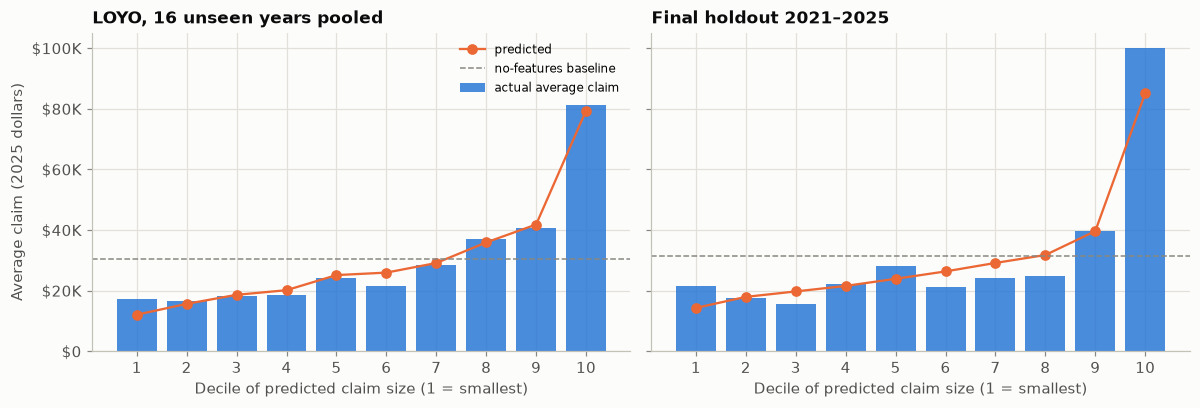

In [19]:
# Decile lift chart: claims ranked by their product of relativities (year-free), 10 equal-count groups.
lt = sv.lift_table(oof[sv.TARGET], oof["pred_rebased"], rank_by=oof["relative_size"])
lt_h = sv.lift_table(te_h[sv.TARGET], mh.predict(te_h), rank_by=mh.relative_size(te_h))
print("LOYO pooled:"); print(lt.round(2).to_string())
print(f"Top / bottom decile actual: {lt['actual_avg'].iloc[-1] / lt['actual_avg'].iloc[0]:.1f}x (LOYO), "
      f"{lt_h['actual_avg'].iloc[-1] / lt_h['actual_avg'].iloc[0]:.1f}x (holdout)")
print(f"Pooled LOYO Gini {sv.size_gini(oof[sv.TARGET], oof['relative_size']):.3f}; holdout Gini {ho['gini']:.3f}")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, t_, name in [(axs[0], lt, "LOYO, 16 unseen years pooled"), (axs[1], lt_h, "Final holdout 2021–2025")]:
    ax.bar(t_.index, t_["actual_avg"], color=BLUE, alpha=0.85, label="actual average claim")
    ax.plot(t_.index, t_["pred_avg"], color=ORANGE, marker="o", label="predicted")
    ax.axhline(t_["actual_total"].sum() / t_["claims"].sum(), color=MUTED, ls="--", lw=1, label="no-features baseline")
    ax.set(title=name, xlabel="Decile of predicted claim size (1 = smallest)")
    ax.set_xticks(t_.index)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(dollars))
axs[0].set_ylabel("Average claim (2025 dollars)")
axs[0].legend(fontsize=8)
fig.tight_layout()
save(fig, "lift_chart")

## 9. Save the model and tables
- `models/severity_glm.json` is the portable model the app reads: spec, coefficients, average-year level, dispersion, the large-loss decision and the ICC bridge factor. It's committed.
- `models/severity_glm.pickle` is the full statsmodels result (gitignored, like the frequency pickle).
- `reports/05_*.csv` hold the tables.

**How it combines with frequency (a preview of the pure-premium milestone):** expected loss cost per policy-year = frequency × severity × ICC bridge. As a sanity check, the two base levels multiplied together should be in the right range for an A/V, 1980–99, 2-storey single-family home.

In [20]:
data_hash = hashlib.sha256(Path(sv.CLAIMS_PATH).read_bytes()).hexdigest()[:16]
rel_json = rel[["feature", "level", "is_base", "claims", "relativity", "lo_cluster", "hi_cluster"]].to_dict(orient="records")
extra = {"description": "Gamma GLM, log link, claim severity (building + contents paid, 2025 dollars), "
                        "one row per paid claim, calendar year as a factor; predict() uses the average-year level.",
         "fitted_on_years": [int(d["year"].min()), int(d["year"].max())], "created": str(date.today()),
         "data_file_sha256_16": data_hash, "claims": int(len(d)), "target": sv.TARGET,
         "recommended_ci": "cluster-robust by county_group x year",
         "base_severity_average_year": BASE_SEV, "icc_bridge_factor": ICC_BRIDGE,
         "large_loss": {"approach": "uncapped (no cap, load 1.0)", "sensitivity_cap_p99": float(cap99),
                        "sensitivity_load_p99": float(sv.large_loss_load(d[sv.TARGET], cap99))},
         "relativities": rel_json}
sv.save_model(final, ROOT / "models" / "severity_glm", extra)
m_back = sv.load_model_json(ROOT / "models" / "severity_glm.json")
assert np.allclose(m_back.predict(d), final.predict(d))
rel.to_csv(ROOT / "reports" / "05_severity_relativities.csv", index=False)
steps.to_csv(ROOT / "reports" / "05_severity_model_steps.csv")
second.to_csv(ROOT / "reports" / "05_severity_second_pass.csv", index=False)
fs.merge(cls.rename(columns={"feature": "label"}), on="label").to_csv(ROOT / "reports" / "05_frequency_vs_severity.csv", index=False)
print("saved models/severity_glm.json (+ .pickle) and reports/05_*.csv")

fj = json.loads((ROOT / "models" / "frequency_glm.json").read_text())
base_freq = fj["base_rate_per_policy_year_average_year"]
print(f"Base frequency {1000 * base_freq:.2f} per 1,000 x base severity ${BASE_SEV:,.0f} x ICC bridge {ICC_BRIDGE:.4f} "
      f"= ${base_freq * BASE_SEV * ICC_BRIDGE:,.0f} per policy-year (statewide average is about $197)")

saved models/severity_glm.json (+ .pickle) and reports/05_*.csv
Base frequency 4.82 per 1,000 x base severity $28,498 x ICC bridge 1.0092 = $139 per policy-year (statewide average is about $197)


## Summary
See `reports/05_severity_glm.md` for the write-up, and `LEARNING_NOTES.md` (Milestone 8) for the concepts explained from scratch.